In [1]:
import pandas as pd

df =pd.read_csv("heart_disease_risk_2026.csv")

print(df.isnull().sum())

patient_id                   0
age                          0
sex                          0
resting_bp_systolic          0
resting_bp_diastolic         0
cholesterol_total            0
hdl                          0
ldl                          0
triglycerides                0
fasting_blood_sugar          0
hba1c                        0
bmi                          0
resting_heart_rate           0
max_heart_rate_achieved      0
chest_pain_type              0
exercise_induced_angina      0
st_depression                0
family_history               0
smoker_status                0
alcohol_units_per_week       0
exercise_minutes_per_week    0
sleep_hours                  0
stress_score                 0
wearable_owner               0
daily_steps                  0
diet_quality_score           0
has_heart_disease            0
dtype: int64


In [ ]:
# print(df["sex"].value_counts())
# df.drop(['patient_id'], inplace=True)
df = df.drop(columns=["chest_pain_type","family_history","patient_id"],axis=1)
print(df.dtypes)
print(df.shape)


KeyError: "['chest_pain_type'] not found in axis"

In [25]:
df = pd.get_dummies(df,columns=["sex","smoker_status"])
# print(df.dtypes)

KeyError: "None of [Index(['sex', 'smoker_status'], dtype='str')] are in the [columns]"

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,recall_score

X = df.drop(columns=["has_heart_disease"])
y =df["has_heart_disease"]


In [19]:
from sklearn.linear_model import LogisticRegression
X_train,X_test,y_train,y_test =train_test_split(X,y,test_size=0.2,random_state=42)

model = LogisticRegression()

model.fit(X_train,y_train)
y_pred_by_logistic = model.predict(X_test)

print("ACCURACY",accuracy_score(y_test,y_pred_by_logistic))

print("confusion_matrix BY LOGISTIC REGRESSION",confusion_matrix(y_test,y_pred_by_logistic))

ACCURACY 0.8333333333333334
confusion_matrix BY LOGISTIC REGRESSION [[1143  101]
 [ 199  357]]


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
X_train,X_test,y_train,y_test =train_test_split(X,y,test_size=0.2,random_state=42)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train,y_train)


prid_val = model.predict(X_test)

print("ACCURACY OF MODEL BY RANDOMFORESTCLASSIFIER", accuracy_score(y_test,prid_val))
print("CONFUSION MATRIX ",confusion_matrix(prid_val,y_test))

ACCURACY OF MODEL BY RANDOMFORESTCLASSIFIER 0.8888888888888888
CONFUSION MATRIX  [[1181  137]
 [  63  419]]


In [29]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

X_train,X_test,y_train,y_test =train_test_split(X,y,test_size=0.2,random_state=42)

model	=	XGBClassifier(
n_estimators=100,
learning_rate=0.1,
max_depth=3,
random_state=42
)

model.fit(X_train,y_train)
pred_val_by_xbg = model.predict(X_test)
print("accuracy_score OF XGBOAST",accuracy_score(y_test,pred_val_by_xbg))
print("confusion matrix" , confusion_matrix(pred_val_by_xbg,y_test))

y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)


accuracy_score OF XGBOAST 0.8933333333333333
confusion matrix [[1175  123]
 [  69  433]]
ROC-AUC: 0.9550605496310346


In [27]:
y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9449103900159616


In [12]:
# CV Scores: [0.89333333 0.89111111 0.89388889 0.89888889 0.88277778]
# Mean Accuracy: 0.892

from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')

print("CV Scores:", scores)
print("Mean Accuracy:", scores.mean())


CV Scores: [0.88722222 0.88611111 0.89       0.90111111 0.88555556]
Mean Accuracy: 0.89


In [30]:
from	lightgbm	import	LGBMClassifier
from sklearn.metrics import roc_auc_score

model	=	LGBMClassifier(
n_estimators=300,
learning_rate=0.05,
max_depth=8,
random_state=42
)
model.fit(X_train,	y_train)
y_pred	=	model.predict(X_test)
print("accuracy_scorebylightgbm: ", accuracy_score(y_test,y_pred))

print("confusion_matrix : \n",confusion_matrix(y_test,y_pred))

y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 2171, number of negative: 5029
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001296 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2871
[LightGBM] [Info] Number of data points in the train set: 7200, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.301528 -> initscore=-0.840033
[LightGBM] [Info] Start training from score -0.840033
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
accuracy_scorebylightgbm:  0.9016666666666666
confusion_matrix : 
 [[1178   66]
 [ 111  445]]
ROC-AUC: 0.9544547641629462


In [8]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')

print("CV Scores:", scores)
print("Mean Accuracy:", scores.mean())

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 2182, number of negative: 5018
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000573 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3130
[LightGBM] [Info] Number of data points in the train set: 7200, number of used features: 32
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.303056 -> initscore=-0.832790
[LightGBM] [Info] Start training from score -0.832790
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 2182, number of negative: 5018
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000627 seconds.
You can set `force_row_wise=true` to 

max_heart_rate_achieved             801
st_depression                       649
ldl                                 541
hdl                                 534
age                                 522
bmi                                 475
stress_score                        436
daily_steps                         436
exercise_minutes_per_week           418
diet_quality_score                  397
alcohol_units_per_week              388
fasting_blood_sugar                 375
sleep_hours                         358
resting_heart_rate                  350
triglycerides                       342
cholesterol_total                   322
hba1c                               305
resting_bp_systolic                 278
resting_bp_diastolic                275
exercise_induced_angina             189
chest_pain_type_Typical Angina      100
chest_pain_type_Asymptomatic         81
smoker_status_Current                79
family_history                       78
sex_Female                           66


<Axes: >

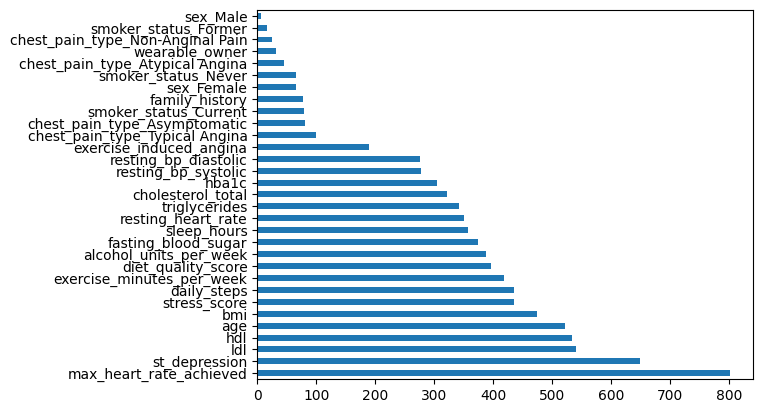

In [23]:
# importance columns

important = pd.Series(model.feature_importances_,index=X.columns)

print(important.sort_values(ascending=False))
import matplotlib.pyplot as plt
important.sort_values(ascending=False).plot(kind='barh')

# plt.show()

In [20]:
# new prediction
n = int(input("ENTER NUMBER OF PATIENTS: "))

for i in range(n):

    print(f"\n------ PATIENT {i+1} ------")

    age = int(input("ENTER AGE: "))
    sex = input("ENTER SEX (Male/Female): ").capitalize()

    resting_bp_systolic = int(input("ENTER RESTING BP SYSTOLIC: "))
    resting_bp_diastolic = int(input("ENTER RESTING BP DIASTOLIC: "))

    cholesterol_total = int(input("ENTER TOTAL CHOLESTEROL: "))
    hdl = int(input("ENTER HDL: "))
    ldl = int(input("ENTER LDL: "))
    triglycerides = int(input("ENTER TRIGLYCERIDES: "))

    fasting_blood_sugar = int(input("ENTER FASTING BLOOD SUGAR: "))
    hba1c = float(input("ENTER HbA1c: "))
    bmi = float(input("ENTER BMI: "))

    resting_heart_rate = int(input("ENTER RESTING HEART RATE: "))
    max_heart_rate_achieved = int(input("ENTER MAX HEART RATE ACHIEVED: "))

    chest_pain_type = input(
        "ENTER CHEST PAIN TYPE (Asymptomatic/Non-Anginal Pain/Atypical Angina/Typical Angina): "
    )

    exercise_induced_angina = input(
        "EXERCISE INDUCED ANGINA (True/False): "
    ).capitalize()

    st_depression = float(input("ENTER ST DEPRESSION: "))

    family_history = input("FAMILY HISTORY (True/False): ").capitalize()

    smoker_status = input(
        "SMOKER STATUS (Never/Former/Current): "
    ).capitalize()

    alcohol_units_per_week = float(
        input("ENTER ALCOHOL UNITS PER WEEK: ")
    )

    exercise_minutes_per_week = int(
        input("ENTER EXERCISE MINUTES PER WEEK: ")
    )

    sleep_hours = float(input("ENTER SLEEP HOURS: "))
    stress_score = float(input("ENTER STRESS SCORE: "))

    wearable_owner = input(
        "WEARABLE OWNER (True/False): "
    ).capitalize()

    daily_steps = int(input("ENTER DAILY STEPS: "))
    diet_quality_score = float(
        input("ENTER DIET QUALITY SCORE: ")
    )


    new_patient = pd.DataFrame({
        "age": [age],
        "sex": [sex],

        "resting_bp_systolic": [resting_bp_systolic],
        "resting_bp_diastolic": [resting_bp_diastolic],

        "cholesterol_total": [cholesterol_total],
        "hdl": [hdl],
        "ldl": [ldl],
        "triglycerides": [triglycerides],

        "fasting_blood_sugar": [fasting_blood_sugar],
        "hba1c": [hba1c],
        "bmi": [bmi],

        "resting_heart_rate": [resting_heart_rate],
        "max_heart_rate_achieved": [max_heart_rate_achieved],

        "chest_pain_type": [chest_pain_type],
        "exercise_induced_angina": [exercise_induced_angina],

        "st_depression": [st_depression],
        "family_history": [family_history],
        "smoker_status": [smoker_status],

        "alcohol_units_per_week": [alcohol_units_per_week],
        "exercise_minutes_per_week": [exercise_minutes_per_week],
        "sleep_hours": [sleep_hours],
        "stress_score": [stress_score],

        "wearable_owner": [wearable_owner],
        "daily_steps": [daily_steps],
        "diet_quality_score": [diet_quality_score]
    })


    # Convert categorical columns into dummy variables
    new_patient = pd.get_dummies(new_patient)

    # Make sure new data has EXACTLY the same columns as training data
    new_patient = new_patient.reindex(columns=X.columns, fill_value=0)


    prediction = model.predict(new_patient)
    # Probability of class 0 and class 1
    probability = model.predict_proba(new_patient)

    prob_0 = probability[0][0] * 100
    prob_1 = probability[0][1] * 100
    print("\n--------------------------------")
    print(f"PATIENT {i+1}")

    if prediction[0] == 1:
        print("Prediction: HAS HEART DISEASE")
    else:
        print("Prediction: NO HEART DISEASE")

    print("--------------------------------")



print(f"Probability of NO HEART DISEASE (0): {prob_0:.2f}%")
print(f"Probability of HAS HEART DISEASE (1): {prob_1:.2f}%")    



------ PATIENT 1 ------

--------------------------------
PATIENT 1
Prediction: HAS HEART DISEASE
--------------------------------
Probability of NO HEART DISEASE (0): 4.81%
Probability of HAS HEART DISEASE (1): 95.19%
